In [3]:
import matplotlib.pyplot as mat
import numpy as np
import pandas as pd
import sys
from pathlib import Path

try:
    base_path = Path(__file__).resolve().parent
except Exception:
    base_path = Path.cwd()
    
if str(base_path) not in sys.path:
    sys.path.insert(0, str(base_path))


coefs = pd.read_csv(base_path / "model_coefs.csv")
best_models = pd.read_csv(base_path / "best_models.csv")

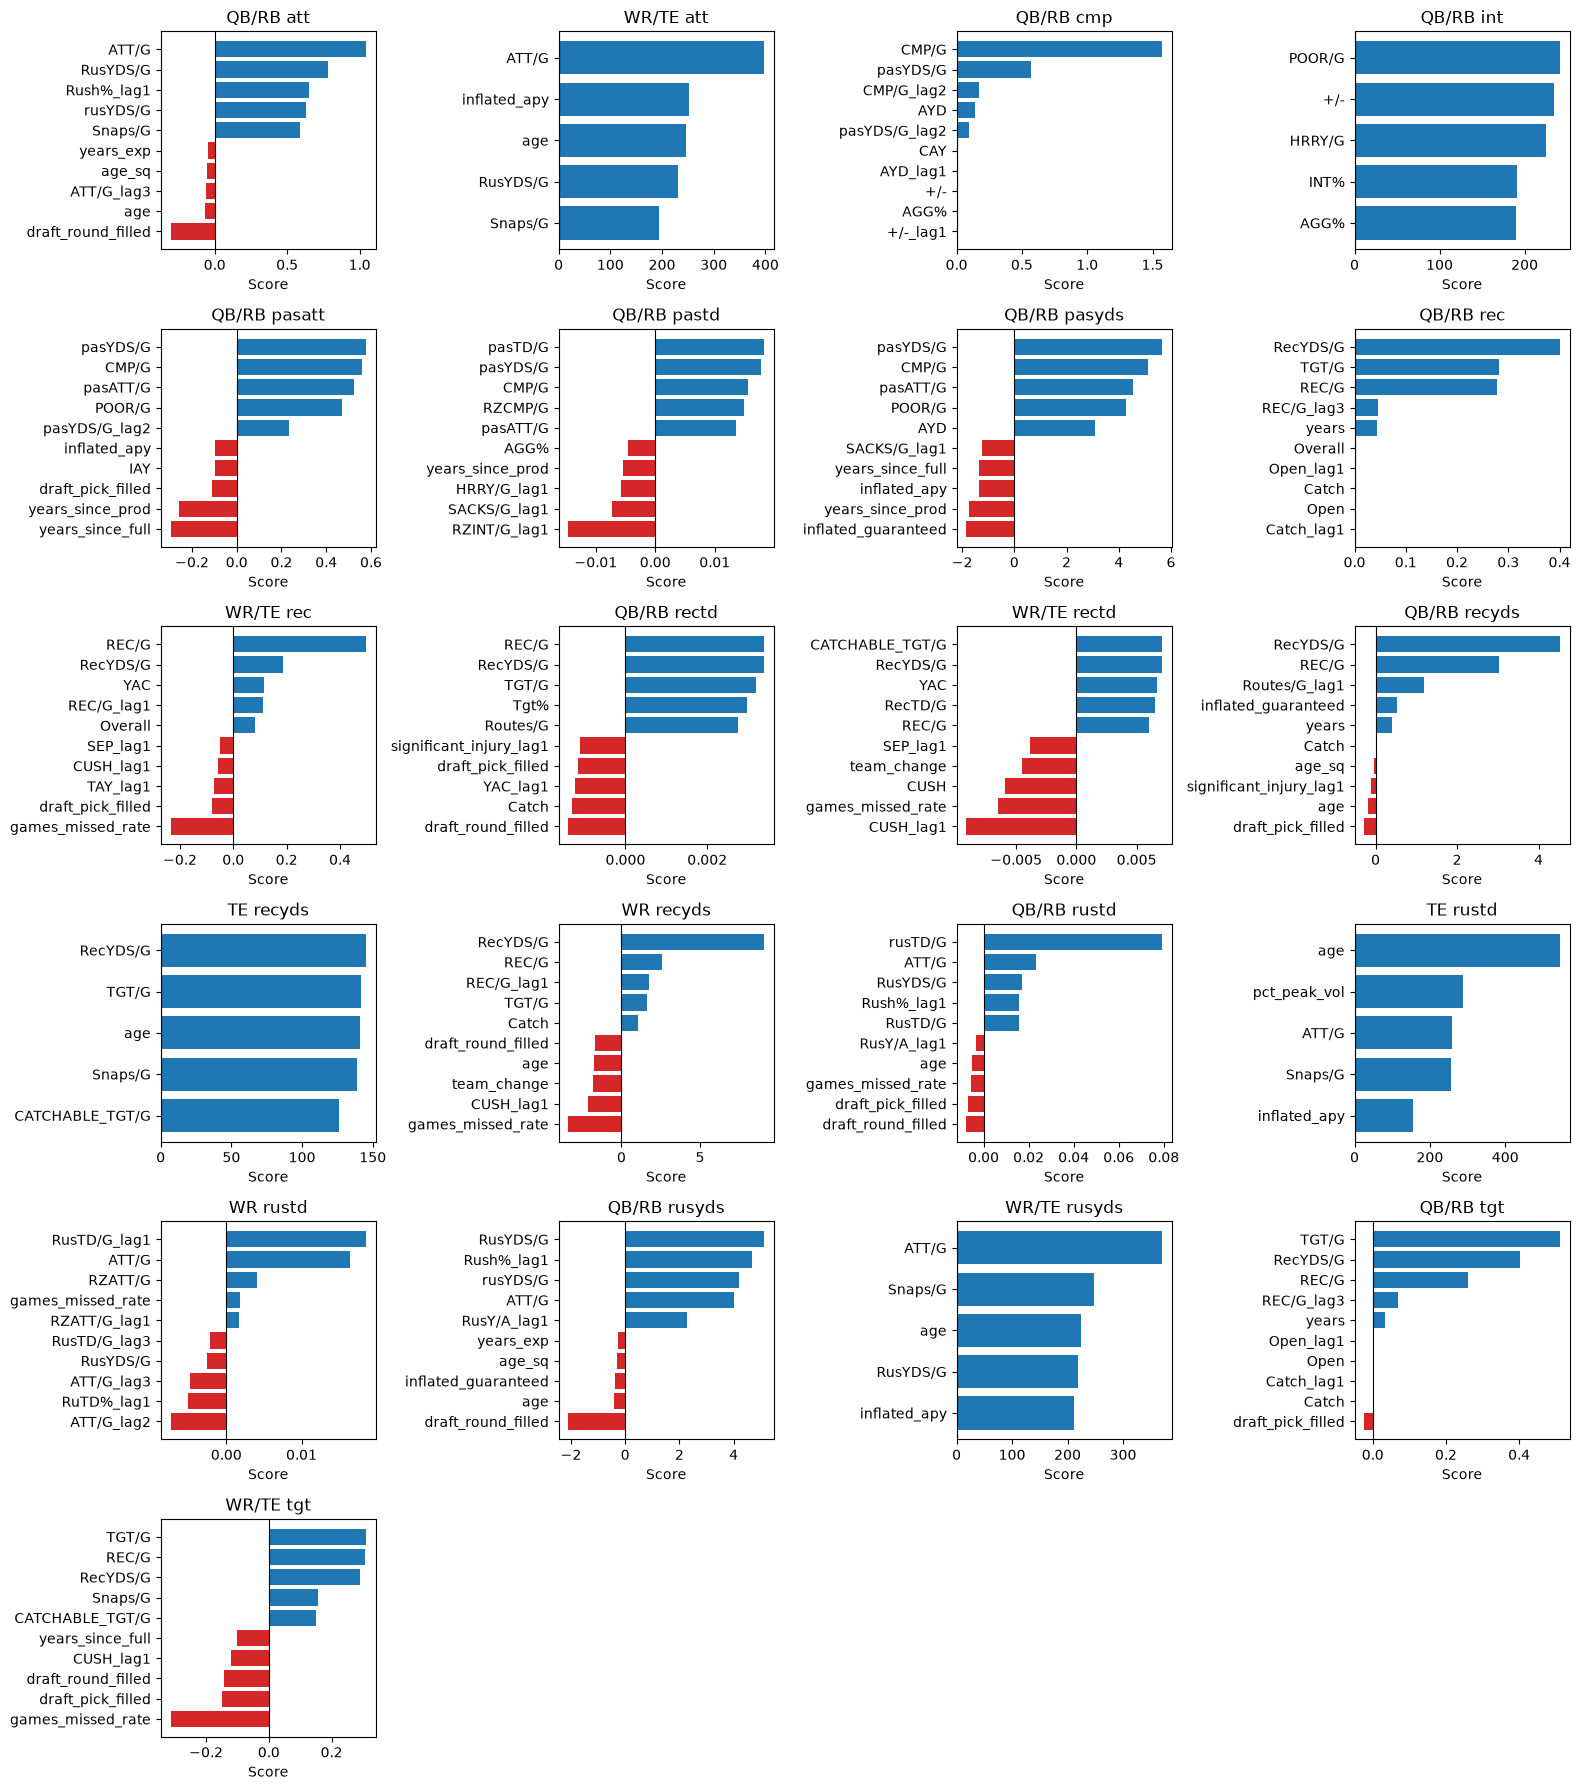

In [4]:
## coefficient comps
pos_group_map = {
    'QB': 'QB/RB',
    'RB': 'QB/RB',
    'WR': 'WR/TE',
    'TE': 'WR/TE'
}

coefs['Pos_group'] = coefs['Pos'].map(pos_group_map)
coefs['score'] = coefs['standardized_coef'].fillna(coefs['importance'])
coefs['source'] = np.where(coefs['standardized_coef'].notna(), 'coef', 'importance')
coefs['Stat'] = coefs['Stat'].str.lower()

def refine_group(row):
    return row['Pos_group']

mixed = coefs.groupby(['Stat', 'Pos_group'])['source'].nunique()
mixed_keys = mixed[mixed > 1].index
mask = coefs.set_index(['Stat', 'Pos_group']).index.isin(mixed_keys)
coefs.loc[mask, 'Pos_group'] = coefs.loc[mask, 'Pos']

grouped = coefs.groupby(['Stat', 'Pos_group', 'feature', 'source'], as_index=False)['score'].mean()

def extremes(stat, pos_group, n=5):
    sub = grouped[(grouped['Stat'] == stat) & (grouped['Pos_group'] == pos_group)].dropna(subset=['score'])
    if sub.empty:
        return None

    result = {}
    for source in sub['source'].unique():
        s = sub[sub['source'] == source]
        if source == 'coef':
            top = s.nlargest(n, 'score')
            last = s.nsmallest(n, 'score')
            result[source] = pd.concat([top, last]).drop_duplicates('feature').sort_values('score')
        else:
            result[source] = s.nlargest(n, 'score').sort_values('score')
    return result

def plot_stat(stat, pos_group, n=5, ax=None):
    if ax is None:
        fig, ax = mat.subplots(figsize=(8, 5))

    result = extremes(stat, pos_group, n)
    if not result:
        ax.set_title(f'{pos_group} - no data'); ax.axis('off')
        return ax

    plot_df = pd.concat(result.values()).drop_duplicates('feature').sort_values('score')

    colors = ['#d62728' if v < 0 else '#1f77b4' for v in plot_df['score']]
    ax.barh(plot_df['feature'], plot_df['score'], color=colors)
    ax.axvline(0, color='black', linewidth=0.8)
    ax.set_title(f'{pos_group} {stat}')
    ax.set_xlabel('Score')
    return ax

combos = (
    grouped[['Stat', 'Pos_group']]
    .drop_duplicates()
    .sort_values(['Stat', 'Pos_group'])
    .itertuples(index=False, name=None)
)
combos = list(combos)
ncols = 4
nrows = int(np.ceil(len(combos) / ncols))
fig, axes = mat.subplots(nrows, ncols, figsize=(4 * ncols, 3 * nrows))

for ax, (stat, pg) in zip(axes.flat, combos):
    plot_stat(stat, pg, n=5, ax=ax)
for ax in axes.flat[len(combos):]:
    ax.axis('off')

mat.tight_layout()
mat.show()


Unmapped stats: <ArrowStringArray>
[]
Length: 0, dtype: str


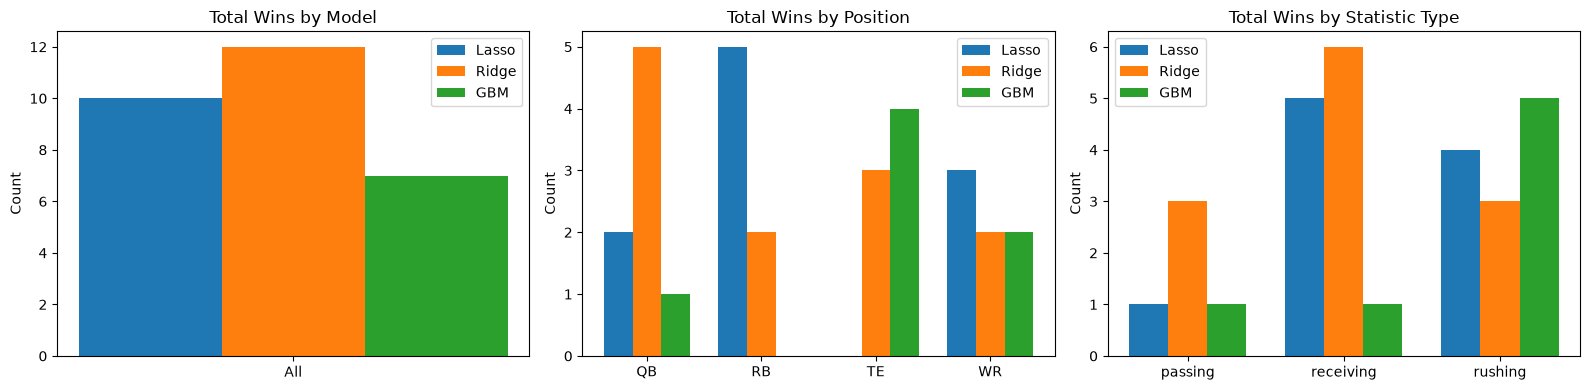

In [3]:
## best model comps
MODELS = ['Lasso', 'Ridge', 'GBM']

def barplot(df, title, ax=None):
    if ax is None:
        fig, ax = mat.subplots(figsize=(6, 4))
    x = np.arange(len(df.index))
    width = 0.25
    for i, model in enumerate(MODELS):
        if model in df.columns:
            ax.bar(x + i * width, df[model].values, width, label=model)
    ax.set_xticks(x + width)
    ax.set_xticklabels(df.index)
    ax.set_ylabel('Count')
    ax.set_title(title)
    ax.legend()
    return ax

# counts by category
by_total = best_models['Best_Model'].value_counts().reindex(MODELS, fill_value=0).to_frame().T
by_total.index = ['All']

by_pos = (
    best_models
    .groupby(['Pos', 'Best_Model'])
    .size()
    .unstack(fill_value=0)
    .reindex(columns=['Lasso', 'Ridge', 'GBM'], fill_value=0)
)

passing = ['CMP', 'pasAtt', 'pasYDS', 'pasTD', 'INT']
rushing = ['ATT', 'rusYDS', 'rusTD']
receiving = ['REC', 'TGT', 'recYDS', 'recTD']

stat_to_type = {}
for s in passing:
    stat_to_type[s.lower()] = 'passing'
for s in rushing:
    stat_to_type[s.lower()] = 'rushing'
for s in receiving:
    stat_to_type[s.lower()] = 'receiving'

best_models['StatType'] = best_models['Stat'].str.lower().map(stat_to_type)

by_type = (
    best_models
    .groupby(['StatType', 'Best_Model'])
    .size()
    .unstack(fill_value=0)
    .reindex(columns=['Lasso', 'Ridge', 'GBM'], fill_value=0)
)

unmapped = best_models.loc[best_models['StatType'].isna(), 'Stat'].unique()
print("Unmapped stats:", unmapped)

# visuals
fig, axes = mat.subplots(1, 3, figsize=(16, 4))
barplot(by_total, 'Total Wins by Model', axes[0])
barplot(by_pos, 'Total Wins by Position', axes[1])
barplot(by_type, 'Total Wins by Statistic Type', axes[2])

mat.tight_layout()
mat.show()